In [1]:

%pip install --upgrade pip
%pip install pandas numpy matplotlib seaborn scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 164.1 kB/s eta 0:00:09
   ---------- ----------------------------- 0.5/2.0 MB 164.1 kB/s eta 0:00:09
   ---------- --

In [2]:
import os
from pathlib import Path

# Search the entire workspace for CSV files
workspace = Path.cwd()

print("YOUR CURRENT LOCATION:", workspace)

csv_files = list(workspace.rglob("*.csv"))

print("\nCSV FILES FOUND:")

if csv_files:
    for file in csv_files:
        print(file)
else:
    print("NO CSV FILES FOUND!")

YOUR CURRENT LOCATION: d:\College_Acadmics\final\Spotify-ana-project-lr\notebook

CSV FILES FOUND:
d:\College_Acadmics\final\Spotify-ana-project-lr\notebook\spotify_churn_dataset.csv
d:\College_Acadmics\final\Spotify-ana-project-lr\notebook\spotify_churn_dataset_local_backup.csv


In [4]:
# ============================================================
#              LINEAR REGRESSION
# ============================================================
sns.set_theme(style="whitegrid")
df = pd.read_csv("spotify_churn_dataset.csv")
print("\nFirst five rows of dataset:")
print(df.head())
print("\nLast five rows of dataset:")
print(df.tail())
print("\nDataset shape (rows, columns):")
print(df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
print(df.describe(include="all"))
print("\nData types:")
print(df.dtypes)
print("\nNumber of unique values:")
print(df.nunique())
print("everything done successfully")


First five rows of dataset:
   user_id  gender  age country subscription_type  listening_time  \
0        1  Female   54      CA              Free              26   
1        2   Other   33      DE            Family             141   
2        3    Male   38      AU           Premium             199   
3        4  Female   22      CA           Student              36   
4        5   Other   29      US            Family             250   

   songs_played_per_day  skip_rate device_type  ads_listened_per_week  \
0                    23       0.20     Desktop                     31   
1                    62       0.34         Web                      0   
2                    38       0.04      Mobile                      0   
3                     2       0.31      Mobile                      0   
4                    57       0.36      Mobile                      0   

   offline_listening  is_churned  
0                  0           1  
1                  1           0  
2           

In [5]:
print("\nMissing values in each column:")
print(df.isnull().sum())
missing_values = df.isnull().sum() # returns pandas series 
print("\n")
print("=" * 60)
print(missing_values)
print("\n")
print("=" * 60)
print(missing_values.sum())

if missing_values.sum() > 0:

    plt.figure(figsize=(10, 5))

    missing_values[missing_values > 0].sort_values().plot(
        kind="bar"
    )

    plt.title("Missing Values in Dataset")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()
    print("SUCCESSFULLY DONE!")

print("\nNumber of duplicate rows:")
print(df.duplicated())
print(df.duplicated().sum())
df = df.drop_duplicates()
df = df.dropna(how="all")
print("\nDataset shape after removing duplicates:")
print(df.shape)


Missing values in each column:
user_id                  0
gender                   0
age                      0
country                  0
subscription_type        0
listening_time           0
songs_played_per_day     0
skip_rate                0
device_type              0
ads_listened_per_week    0
offline_listening        0
is_churned               0
dtype: int64


user_id                  0
gender                   0
age                      0
country                  0
subscription_type        0
listening_time           0
songs_played_per_day     0
skip_rate                0
device_type              0
ads_listened_per_week    0
offline_listening        0
is_churned               0
dtype: int64


0

Number of duplicate rows:
0       False
1       False
2       False
3       False
4       False
        ...  
7995    False
7996    False
7997    False
7998    False
7999    False
Length: 8000, dtype: bool
0

Dataset shape after removing duplicates:
(8000, 12)


In [6]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

df.to_csv("spotify_cleaned.csv", index=False)
print("\nCleaned dataset saved successfully!")



Numerical columns:
['user_id', 'age', 'listening_time', 'songs_played_per_day', 'skip_rate', 'ads_listened_per_week', 'offline_listening', 'is_churned']

Categorical columns:
['gender', 'country', 'subscription_type', 'device_type']

Cleaned dataset saved successfully!


C:\Users\SARTHAK\AppData\Local\Temp\ipykernel_19584\2996636159.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [7]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

df.to_csv("spotify_cleaned.csv", index=False)
print("\nCleaned dataset saved successfully!")  


Numerical columns:
['user_id', 'age', 'listening_time', 'songs_played_per_day', 'skip_rate', 'ads_listened_per_week', 'offline_listening', 'is_churned']

Categorical columns:
['gender', 'country', 'subscription_type', 'device_type']

Cleaned dataset saved successfully!


C:\Users\SARTHAK\AppData\Local\Temp\ipykernel_19584\940787811.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


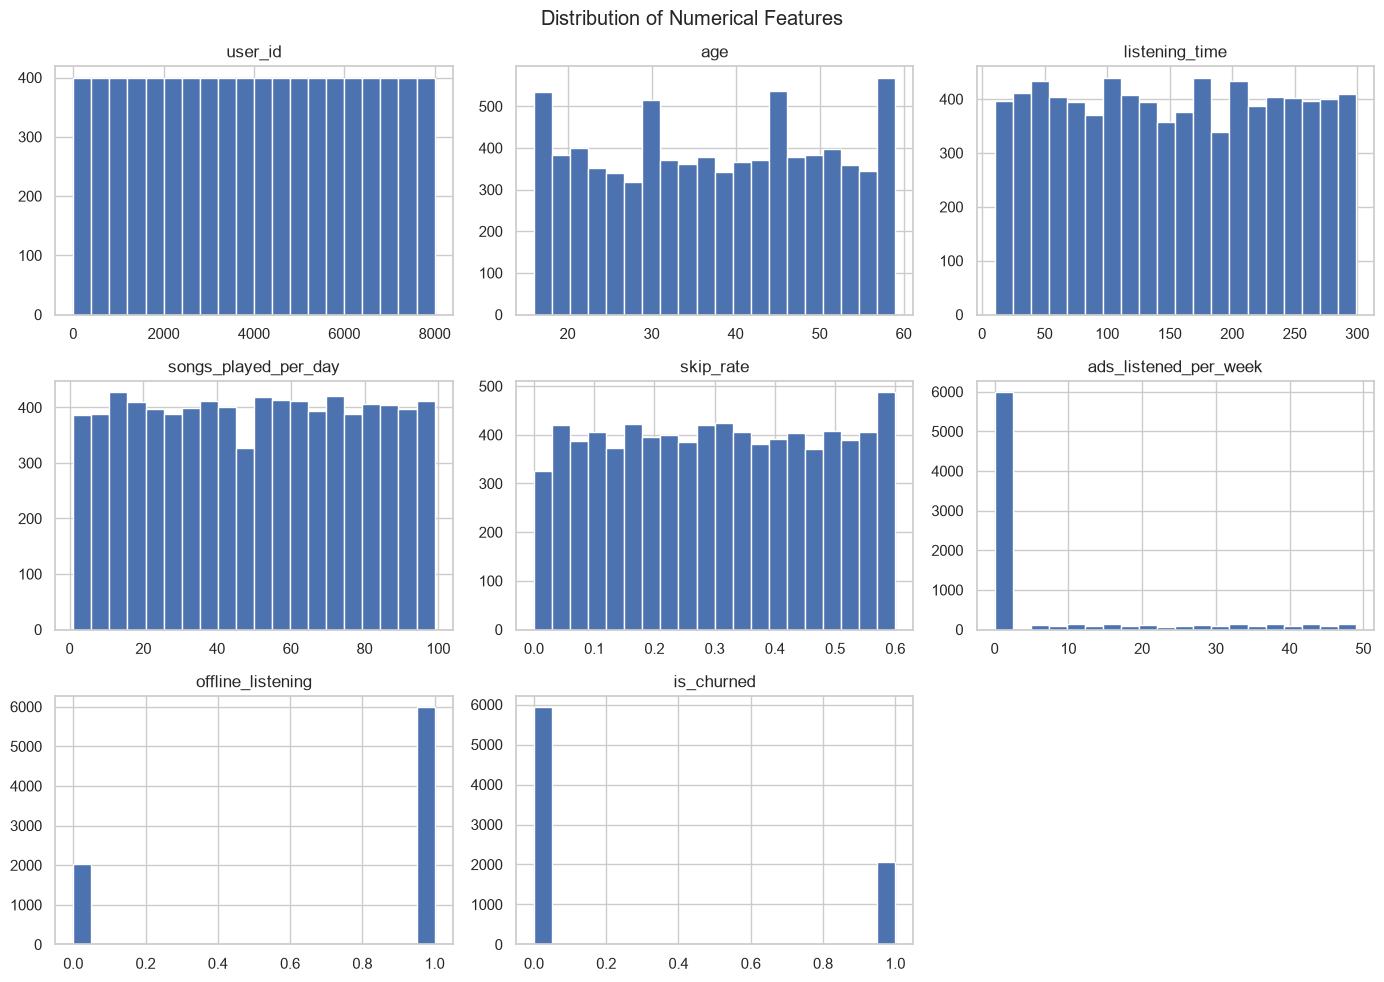

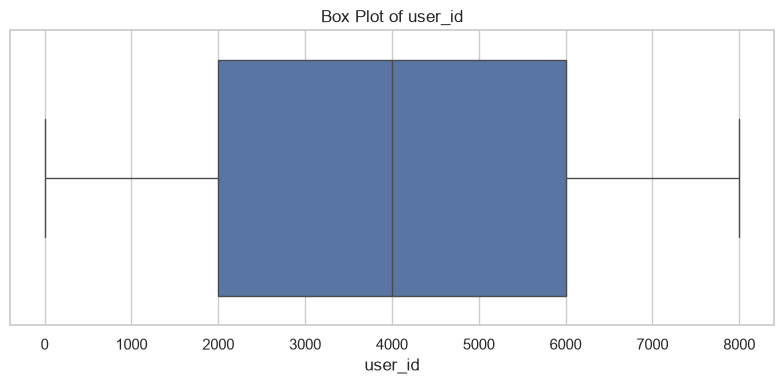

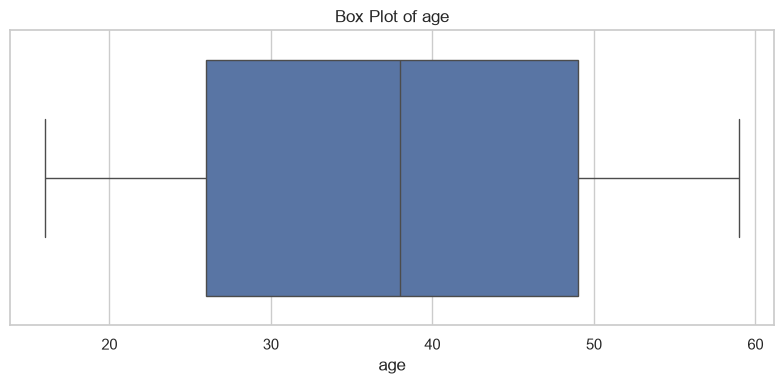

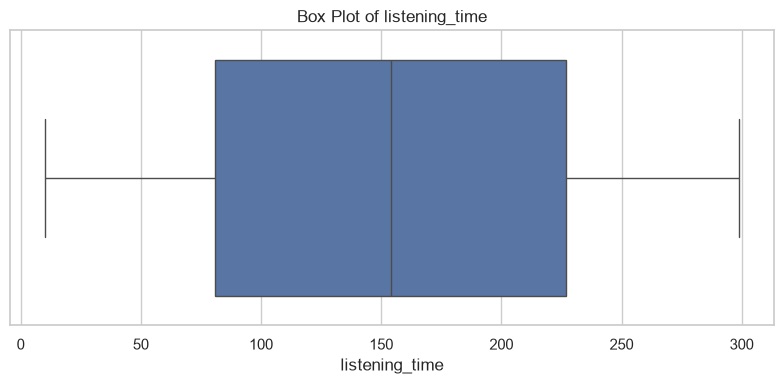

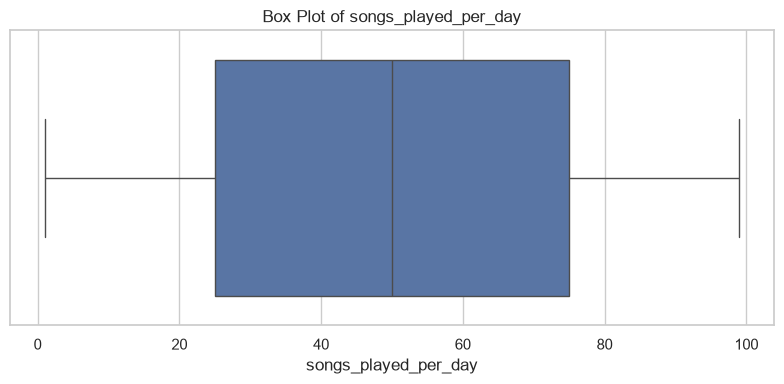

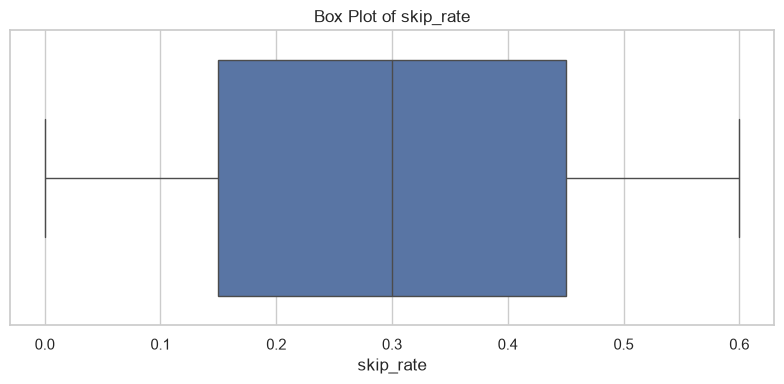

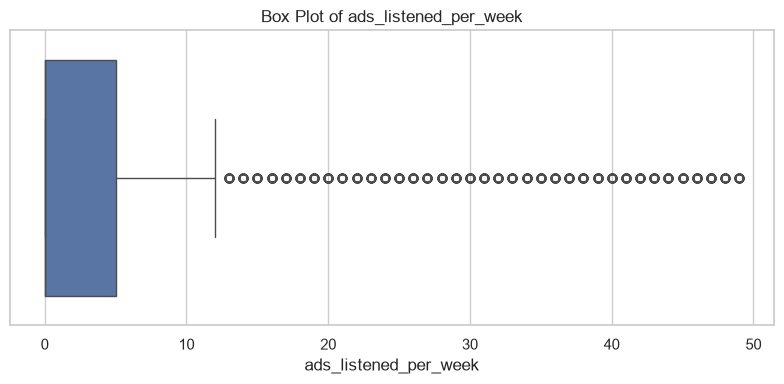

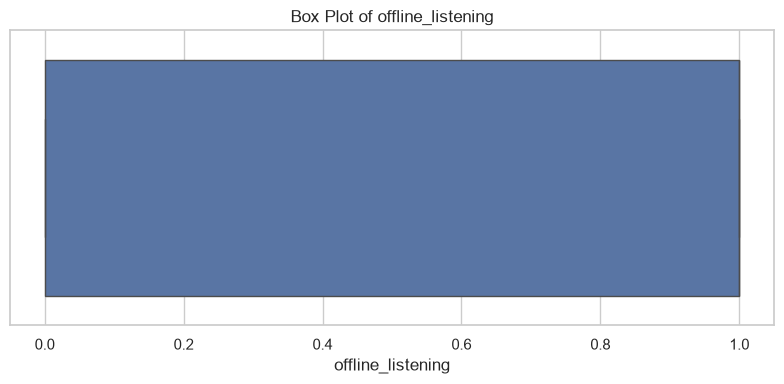

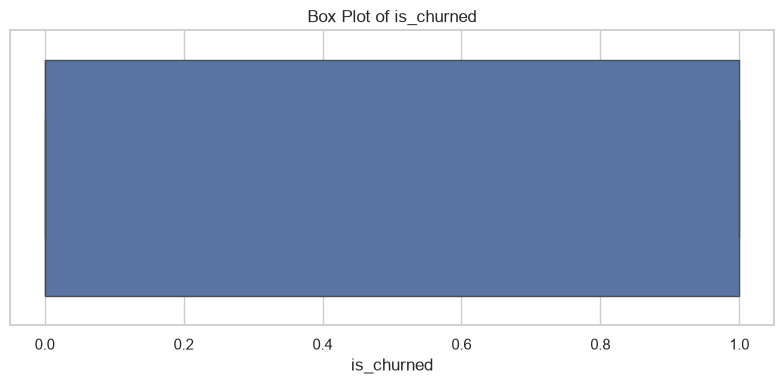

In [8]:
# Histogram Plot

if len(numeric_columns) > 0:

    df[numeric_columns].hist(
        figsize=(14, 10),
        bins=20
    )

    plt.suptitle("Distribution of Numerical Features")
    plt.tight_layout()

    plt.show()


# Box Plot

for column in numeric_columns[:8]:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[column])

    plt.title("Box Plot of " + column)
    plt.xlabel(column)

    plt.tight_layout()

    plt.show()